# TF Site x Kinase Module Heatmap

Subsetted down to just the two heatmaps: the full version (all modules) and the final version (modules 4, 9, 10, 12 excluded).

## 0. Imports & paths

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import fisher_exact
import kinase_library as kl

sig_sites_f    = "/ix/djishnu/Aaron_F/proteomics_proj/Data/phosphoproteomics/significant_phospho_pairwise_res.csv"
phospho_data_f = "/ix/djishnu/Aaron_F/proteomics_proj/Data/phosphoproteomics/stat_results_IL6IL10phosphopairwiseBMDMheatmap.csv"

tf1_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/DEG_motif_enrichment/common_degs_enr/sig_TF_results/out_files/sig_tomtom_TFs_withLabels.csv"
tf2_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/modisco/out_files/sig_modisco_TFs_withLabels.csv"
tf3_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/decoupler/out_files/sig_decoupler_TFs_withLabels.csv"

module_assignments_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_module_heatmap/out_files/kinase_module_assignments.csv"

out_dir = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/site_module_heatmap"
fig_out = f"{out_dir}/figures"
os.makedirs(fig_out, exist_ok=True)
os.makedirs(f"{out_dir}/out_files", exist_ok=True)

KL_THRESH = 15  # must match kl_thresh used for ser_thr in the MEA generation script

## 1. Load kinase modules and dynamic Ser/Thr TF sites

In [2]:
module_df = pd.read_csv(module_assignments_f)

sig_sites = pd.read_csv(sig_sites_f)
sig_sites['geneSymbol'] = sig_sites['id'].str.split('_').str[0]
sig_sites['id']         = sig_sites['id'].str.split('_', n=1).str[1]
sig_sites_list          = sig_sites.id.tolist()

prot_df = pd.read_csv(phospho_data_f)
prot_df['geneSymbol'] = prot_df['id'].str.split('_').str[0]
prot_df['id']         = prot_df['id'].str.split('_', n=1).str[1]
prot_df = prot_df[["id", "geneSymbol", "VMsiteFlanks"]]

dyn_sites = prot_df.loc[prot_df.id.isin(sig_sites_list)].copy().reset_index(drop=True)

tf1_genes = pd.read_csv(tf1_f).loc[lambda d: d.is_expressed, "tf_symbol"].tolist()
tf2_genes = pd.read_csv(tf2_f).loc[lambda d: d.is_expressed, "tf_symbol"].tolist()
tf3_genes = pd.read_csv(tf3_f).loc[lambda d: d.is_expressed, "tf_symbol"].tolist()
tf_genes = list(set(tf1_genes + tf2_genes + tf3_genes))

dyn_tf_sites = dyn_sites.loc[dyn_sites.geneSymbol.isin(tf_genes)].copy().reset_index(drop=True)
dyn_tf_sites["site_label"] = dyn_tf_sites["geneSymbol"] + "_" + dyn_tf_sites["id"].str.split("_").str[1]
dup_mask = dyn_tf_sites["site_label"].duplicated(keep=False)
if dup_mask.any():
    suffix = dyn_tf_sites.groupby("site_label").cumcount().astype(str)
    dyn_tf_sites.loc[dup_mask, "site_label"] += "_dup" + suffix[dup_mask]

def get_site_type(seq):
    if 'y' in seq:
        return 'tyrosine'
    elif 's' in seq or 't' in seq:
        return 'ser_thr'
    return None

dyn_tf_sites["kin_type"] = dyn_tf_sites["VMsiteFlanks"].str.split("|").str[0].apply(get_site_type)
dyn_tf_sites_serthr = dyn_tf_sites.loc[dyn_tf_sites.kin_type == "ser_thr"].copy().reset_index(drop=True)

print(f"Module-labeled kinases: {len(module_df)}  |  "
      f"Dynamic Ser/Thr TF sites: {len(dyn_tf_sites_serthr)} "
      f"(dropped {len(dyn_tf_sites) - len(dyn_tf_sites_serthr)} tyrosine/unclassified)")

Module-labeled kinases: 83  |  Dynamic Ser/Thr TF sites: 38 (dropped 4 tyrosine/unclassified)


## 2. Score each TF site against the Ser/Thr kinase panel (percentile rank)

In [3]:
flank_df = (
    dyn_tf_sites_serthr[['id', 'site_label', 'VMsiteFlanks']]
    .assign(VMsiteFlanks=lambda df: df.VMsiteFlanks.str.split('|'))
    .explode('VMsiteFlanks')
    .rename(columns={'VMsiteFlanks': 'sequence'})
    .dropna(subset=['sequence'])
    .assign(sequence=lambda df: df.sequence.str.strip())
    .reset_index(drop=True)
)

pps_data = kl.PhosphoProteomics(flank_df, seq_col='sequence')
pps_data.percentile(kin_type='ser_thr', values_only=True)
percentile_ranks = pps_data.ser_thr_percentile_ranks.copy()
percentile_ranks['id'] = flank_df['id'].values
percentile_ranks['site_label'] = flank_df['site_label'].values

long = percentile_ranks.melt(id_vars=['id', 'site_label'], var_name='kinase', value_name='percentile_rank')
long['kinase'] = long['kinase'].str.upper()

# collapse isoform-flank duplicates per site: best (lowest) rank across variants
site_kinase_rank = (
    long.groupby(['site_label', 'kinase'])['percentile_rank']
    .min()
    .reset_index()
)
print(f"Scored {site_kinase_rank.site_label.nunique()} sites x {site_kinase_rank.kinase.nunique()} kinases")

Scoring 42 ser_thr substrates
Calculating percentile for 42 ser_thr substrates


Percentile scoring: 100%|██████████| 311/311 [00:00<00:00, 42408.03it/s]

Scored 38 sites x 311 kinases


## 3. Top-15 predicted kinases per site (input to the module enrichment test)

In [4]:
top15_per_site = (
    site_kinase_rank[site_kinase_rank["percentile_rank"] <= KL_THRESH]
    .sort_values(["site_label", "percentile_rank"])
)
print(f"Top-15 kinase assignments: {top15_per_site.shape[0]} rows")

Top-15 kinase assignments: 621 rows


## 4. Module enrichment per TF site (Fisher's exact) -- produces `enrich_df`

In [5]:
module_kinase_set = set(module_df["kinase"])
kinase_to_module  = dict(zip(module_df["kinase"], module_df["module"]))
module_ids        = sorted(module_df["module"].unique())
module_sizes      = module_df["module"].value_counts()
total_kinases     = len(module_kinase_set)

candidates = top15_per_site[top15_per_site["kinase"].isin(module_kinase_set)].copy()
candidates["module"] = candidates["kinase"].map(kinase_to_module)

results = []
for site, site_cands in candidates.groupby("site_label"):
    n_cand = len(site_cands)
    cand_modules = site_cands["module"].value_counts()
    for m in module_ids:
        a = cand_modules.get(m, 0)
        b = n_cand - a
        c = module_sizes.get(m, 0) - a
        d = total_kinases - n_cand - c
        odds_ratio, p = fisher_exact([[a, b], [c, d]], alternative="greater")
        results.append({"site_label": site, "module": m, "n_candidates_in_module": a,
                         "n_candidates_total": n_cand, "module_size": module_sizes.get(m, 0),
                         "odds_ratio": odds_ratio, "p_value": p})

enrich_df = pd.DataFrame(results)
enrich_df["neg_log10_p"] = -np.log10(enrich_df["p_value"].clip(lower=1e-300))
print(f"Sites with >=1 module-labeled candidate kinase: {candidates.site_label.nunique()} / "
      f"{top15_per_site.site_label.nunique()}")

# save the enrichment table itself -- kinase_tf_group_panel.ipynb reads a
# saved module-vs-TF summary CSV; this is that file, produced by this
# notebook directly rather than an unseen separate script
summary_out = f"{out_dir}/out_files/tf_module_overlap_summary.csv"
enrich_df.to_csv(summary_out, index=False)
print(f"Saved: {summary_out}")

Sites with >=1 module-labeled candidate kinase: 36 / 38
Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/site_module_heatmap/out_files/tf_module_overlap_summary.csv


## 5. FULL heatmap -- TF site x module (-log10 p-value), all modules

SVG is rasterized (heatmap body only) so the file stays small -- a true-vector heatmap would draw one path per cell.

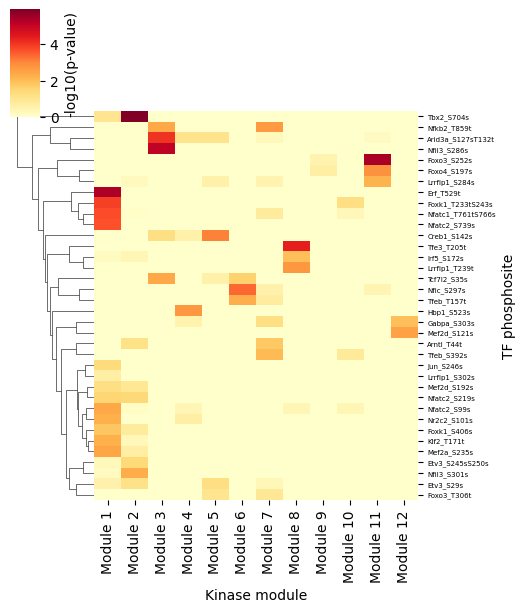

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/site_module_heatmap/figures/tf_site_module_enrichment_heatmap_full.png
Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/site_module_heatmap/figures/tf_site_module_enrichment_heatmap_full.svg


In [6]:
pivot = enrich_df.pivot(index="site_label", columns="module", values="neg_log10_p")
pivot.columns = [f"Module {m}" for m in pivot.columns]

g = sns.clustermap(
    pivot.fillna(0), cmap="YlOrRd", col_cluster=False,
    figsize=(6, max(6, 0.15 * len(pivot))),
    yticklabels=True, xticklabels=True,
    cbar_kws={"label": "-log10(p-value)"}
)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), fontsize=5)
g.ax_heatmap.set_xlabel("Kinase module")
g.ax_heatmap.set_ylabel("TF phosphosite")

for collection in g.ax_heatmap.collections:
    collection.set_rasterized(True)

png_out = f"{fig_out}/tf_site_module_enrichment_heatmap_full.png"
svg_out = f"{fig_out}/tf_site_module_enrichment_heatmap_full.svg"
g.savefig(png_out, dpi=300, bbox_inches="tight")
g.savefig(svg_out, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {png_out}")
print(f"Saved: {svg_out}")

## 6. FINAL heatmap -- modules 4, 9, 10, 12 excluded

Dropping columns (modules), not rows (sites) this time -- clustermap re-clusters rows fresh on the reduced set of columns, since removing modules changes each site's enrichment profile and therefore how sites should group together.

Modules: 12 -> 7 after excluding [4, 9, 10, 12] and merging 5+6


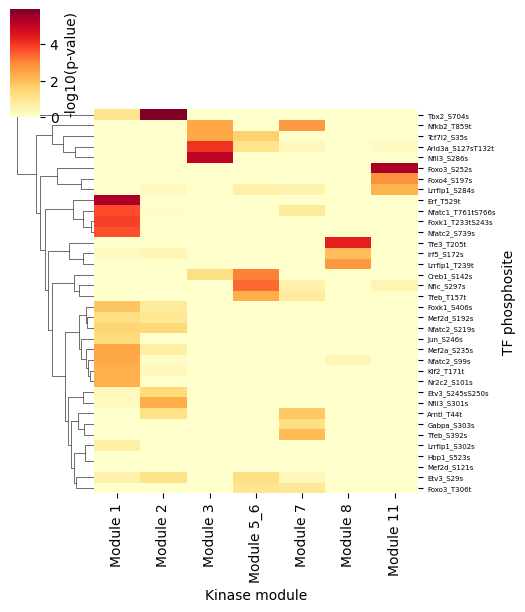

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/site_module_heatmap/figures/tf_site_module_enrichment_heatmap_final.png
Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/site_module_heatmap/figures/tf_site_module_enrichment_heatmap_final.svg


In [7]:
EXCLUDED_MODULES = [4, 9, 10, 12]

# Merge modules 5 and 6 into one combined "Module 5_6" column, same
# meta-module grouping as the fig3a kinase heatmap. Combined via
# max(neg_log10_p) across the two -- i.e. whichever of the two module
# tests gave the stronger (more significant) signal for that site --
# rather than summing/averaging, since these are already -log10(p)
# values from two separate Fisher's exact tests, and taking the
# stronger signal is the defensible way to combine two significance
# tests into one displayed value.
MODULE_MERGE = {5: "5_6", 6: "5_6"}

def display_module(m):
    return MODULE_MERGE.get(m, m)

modules_present_raw = [m for m in module_ids if m not in EXCLUDED_MODULES]
display_order = sorted(
    set(display_module(m) for m in modules_present_raw),
    key=lambda d: min(m for m in modules_present_raw if display_module(m) == d),
)

pivot_final = pd.DataFrame(index=pivot.index)
for d in display_order:
    raw_modules = [m for m in modules_present_raw if display_module(m) == d]
    cols = [f"Module {m}" for m in raw_modules if f"Module {m}" in pivot.columns]
    pivot_final[f"Module {d}"] = pivot[cols].max(axis=1)

print(f"Modules: {pivot.shape[1]} -> {pivot_final.shape[1]} after excluding {EXCLUDED_MODULES} and merging 5+6")

g_final = sns.clustermap(
    pivot_final.fillna(0), cmap="YlOrRd", col_cluster=False,
    figsize=(6, max(6, 0.15 * len(pivot_final))),
    yticklabels=True, xticklabels=True,
    cbar_kws={"label": "-log10(p-value)"}
)
g_final.ax_heatmap.set_yticklabels(g_final.ax_heatmap.get_yticklabels(), fontsize=5)
g_final.ax_heatmap.set_xlabel("Kinase module")
g_final.ax_heatmap.set_ylabel("TF phosphosite")

for collection in g_final.ax_heatmap.collections:
    collection.set_rasterized(True)

png_out_final = f"{fig_out}/tf_site_module_enrichment_heatmap_final.png"
svg_out_final = f"{fig_out}/tf_site_module_enrichment_heatmap_final.svg"
g_final.savefig(png_out_final, dpi=300, bbox_inches="tight")
g_final.savefig(svg_out_final, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {png_out_final}")
print(f"Saved: {svg_out_final}")